# Notebook 01 – Khám phá và tiền xử lý UD Vietnamese-VTB cho POS Tagging

**Mục tiêu:** đọc ba tập CoNLL-U, kiểm tra chất lượng dữ liệu, thực hiện EDA, ánh xạ nhãn UPOS về 5 nhóm và chuẩn bị dữ liệu đầu vào ở mức từ cho PhoBERT.

**Lưu ý phương pháp**
- Giữ nguyên ba tập `train`, `dev`, `test` do dataset cung cấp.
- Dùng cột `UPOS` (cột thứ 4 trong CoNLL-U) làm nhãn gốc; không trộn với `XPOS`.
- Không chạy lại word segmentation trên dữ liệu đã gán nhãn.
- Giữ nguyên token gốc và nhãn tương ứng. Khi tạo câu cho PhoBERT, thay khoảng trắng *bên trong một token* bằng `_` (ví dụ `chủ tịch` → `chủ_tịch`).
- Chưa thực hiện BPE/subword alignment trong notebook này; đó là bước tích hợp với tokenizer ở giai đoạn mô hình.

## 0. Chuẩn bị môi trường và nạp dữ liệu

Notebook chạy được trên Google Colab hoặc Jupyter local. Nếu chạy Colab, tải `Dataset.zip` lên khi được yêu cầu. Nếu chạy local, đặt file ZIP cùng thư mục với notebook hoặc sửa `ZIP_PATH`.

In [1]:
from pathlib import Path
import zipfile
import unicodedata
import re
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ---- Xác định thư mục project (chạy local trong VS Code) ----
# VS Code Jupyter thường đặt cwd = thư mục chứa notebook (Pos_tagging/Notebooks)
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name.lower() == "notebooks" else NOTEBOOK_DIR

ZIP_NAME = "RawData.zip"   # đổi tên này nếu file zip của bạn tên khác

CANDIDATE_PATHS = [
    PROJECT_ROOT / "Data" / ZIP_NAME,   # Pos_tagging/Data/RawData.zip  (vị trí chính)
    NOTEBOOK_DIR / ZIP_NAME,            # cùng thư mục với notebook
    PROJECT_ROOT / ZIP_NAME,            # ngay tại thư mục gốc project
]

ZIP_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if ZIP_PATH is None:
    tried = "\n".join(f"  - {p}" for p in CANDIDATE_PATHS)
    raise FileNotFoundError(
        f"Không tìm thấy {ZIP_NAME}. Đã thử các đường dẫn:\n{tried}\n"
        f"Hãy đặt file vào thư mục Data/ hoặc sửa ZIP_NAME / CANDIDATE_PATHS."
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", ZIP_PATH)

Project root: D:\Downloads\new_data_science\NEW PROJECTS\Pos_tagging
Dataset: D:\Downloads\new_data_science\NEW PROJECTS\Pos_tagging\Data\RawData.zip


In [3]:
EXTRACT_DIR = PROJECT_ROOT / "Data" / "data_vtb"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

conllu_files = sorted(EXTRACT_DIR.rglob("*.conllu"))
print("Số file CoNLL-U tìm thấy:", len(conllu_files))
for p in conllu_files:
    print("-", p.relative_to(PROJECT_ROOT))

Số file CoNLL-U tìm thấy: 3
- Data\data_vtb\Dataset\vi_vtb-ud-dev.conllu
- Data\data_vtb\Dataset\vi_vtb-ud-test.conllu
- Data\data_vtb\Dataset\vi_vtb-ud-train.conllu


## 1. Đọc file CoNLL-U

CoNLL-U có 10 cột. Các dòng có ID dạng `1-2` (multiword-token range) hoặc `1.1` (empty node) không phải token độc lập để huấn luyện POS thông thường, nên được ghi nhận và bỏ khỏi danh sách token. Các dòng bình thường có ID là số nguyên sẽ được giữ lại.

In [4]:
CONLLU_COLUMNS = [
    "id", "form", "lemma", "upos", "xpos",
    "feats", "head", "deprel", "deps", "misc"
]

def parse_conllu_file(path, split_name):
    sentences = []
    current_tokens = []
    current_comments = []

    def flush_sentence():
        nonlocal current_tokens, current_comments
        if current_tokens:
            sentences.append({
                "split": split_name,
                "sentence_id": f"{split_name}_{len(sentences)+1:05d}",
                "comments": current_comments.copy(),
                "tokens": current_tokens.copy()
            })
        current_tokens = []
        current_comments = []

    with open(path, "r", encoding="utf-8-sig") as f:
        for line_no, raw_line in enumerate(f, start=1):
            line = raw_line.rstrip("\n\r")

            if not line.strip():
                flush_sentence()
                continue

            if line.startswith("#"):
                current_comments.append(line)
                continue

            fields = line.split("\t")
            if len(fields) != 10:
                raise ValueError(
                    f"{path.name}, dòng {line_no}: cần 10 cột, nhận được {len(fields)}"
                )

            token_id = fields[0]
            # Chỉ giữ token có ID nguyên: bỏ multiword range và empty nodes.
            if not token_id.isdigit():
                continue

            current_tokens.append(dict(zip(CONLLU_COLUMNS, fields)))

    flush_sentence()
    return sentences

split_paths = {}
for p in conllu_files:
    name = p.name.lower()
    if "train" in name:
        split_paths["train"] = p
    elif "dev" in name or "valid" in name:
        split_paths["dev"] = p
    elif "test" in name:
        split_paths["test"] = p

required_splits = {"train", "dev", "test"}
assert required_splits.issubset(split_paths), (
    f"Thiếu tập dữ liệu: {required_splits - set(split_paths)}"
)

data = {
    split: parse_conllu_file(path, split)
    for split, path in split_paths.items()
}

for split, sentences in data.items():
    n_tokens = sum(len(s["tokens"]) for s in sentences)
    print(f"{split:>5}: {len(sentences):,} câu | {n_tokens:,} token")

  dev: 1,123 câu | 26,162 token
 test: 800 câu | 11,692 token
train: 1,400 câu | 20,215 token


## 2. Chuyển thành DataFrame và kiểm tra cấu trúc

Mỗi dòng của `sentence_df` là một câu; mỗi dòng của `token_df` là một token. Giữ hai bảng riêng giúp thống kê thuận tiện mà vẫn bảo toàn cấu trúc câu.

In [5]:
sentence_rows = []
token_rows = []

for split, sentences in data.items():
    for sent in sentences:
        tokens = sent["tokens"]
        sentence_rows.append({
            "split": split,
            "sentence_id": sent["sentence_id"],
            "n_tokens": len(tokens),
            "forms": [t["form"] for t in tokens],
            "upos": [t["upos"] for t in tokens],
        })
        for position, token in enumerate(tokens, start=1):
            token_rows.append({
                "split": split,
                "sentence_id": sent["sentence_id"],
                "position": position,
                **token
            })

sentence_df = pd.DataFrame(sentence_rows)
token_df = pd.DataFrame(token_rows)

display(sentence_df.head())
display(token_df.head())
print("Kích thước sentence_df:", sentence_df.shape)
print("Kích thước token_df:", token_df.shape)

,split,sentence_id,n_tokens,forms,upos
0,dev,dev_00001,46,"[Trả lời, phỏng vấn, ,, ông, Lộc, nói, :, bán,...","[VERB, VERB, PUNCT, NOUN, PROPN, VERB, PUNCT, ..."
1,dev,dev_00002,32,"[Công trình, đường, Trương Định, nối, dài, LBK...","[NOUN, NOUN, PROPN, VERB, ADJ, PUNCT, NOUN, PR..."
2,dev,dev_00003,28,"[Họ, đưa, chúng tôi, đến, khu vực, công trường...","[NOUN, VERB, NOUN, VERB, NOUN, NOUN, NOUN, NOU..."
3,dev,dev_00004,44,"[Chiều, 23-3, ,, trả lời, Tuổi Trẻ, sau, phiên...","[NOUN, NUM, PUNCT, VERB, PROPN, NOUN, NOUN, VE..."
4,dev,dev_00005,11,"[Thưa, ông, ,, sổ đỏ, đã, được, giao, cho, ngư...","[VERB, NOUN, PUNCT, NOUN, ADV, AUX, VERB, ADP,..."


,split,sentence_id,position,id,form,lemma,upos,xpos,feats,head,deprel,deps,misc
0,dev,dev_00001,1,1,Trả lời,trả lời,VERB,V,_,6,advcl,_,_
1,dev,dev_00001,2,2,phỏng vấn,phỏng vấn,VERB,V,_,1,xcomp,_,_
2,dev,dev_00001,3,3,",",",",PUNCT,PUNCT,_,6,punct,_,_
3,dev,dev_00001,4,4,ông,ông,NOUN,N,_,5,clf:det,_,_
4,dev,dev_00001,5,5,Lộc,Lộc,PROPN,NNP,_,6,nsubj,_,_


Kích thước sentence_df: (3323, 5)
Kích thước token_df: (58069, 13)


## 3. Thống kê tổng quan dữ liệu (mục 3.2)

Thống kê số câu, số token, độ dài câu trung bình, ngắn nhất và dài nhất cho từng tập.

In [6]:
summary_rows = []
for split in ["train", "dev", "test"]:
    s_df = sentence_df[sentence_df["split"] == split]
    t_df = token_df[token_df["split"] == split]
    lengths = s_df["n_tokens"]

    summary_rows.append({
        "Tập": split,
        "Số câu": len(s_df),
        "Số token": len(t_df),
        "Token/câu trung bình": round(lengths.mean(), 2),
        "Ngắn nhất": int(lengths.min()),
        "Trung vị": float(lengths.median()),
        "Dài nhất": int(lengths.max()),
        "Số FORM duy nhất": t_df["form"].nunique()
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)
print("Tổng cộng:", f"{len(sentence_df):,} câu,", f"{len(token_df):,} token")

,Tập,Số câu,Số token,Token/câu trung bình,Ngắn nhất,Trung vị,Dài nhất,Số FORM duy nhất
0,train,1400,20215,14.44,2,14.0,25,3870
1,dev,1123,26162,23.30,3,21.0,96,4818
2,test,800,11692,14.62,2,15.0,25,2475


Tổng cộng: 3,323 câu, 58,069 token


## 4. Phân bố 17 nhãn UPOS gốc

Đây là thống kê trước khi gộp nhãn. Không dùng XPOS cho bước ánh xạ chính.

,upos,count,percentage
0,NOUN,16489,28.395529
1,VERB,10868,18.715666
2,PUNCT,8151,14.036749
3,ADV,4144,7.136338
4,ADP,3392,5.841327
5,ADJ,3380,5.820662
6,PROPN,2515,4.331054
7,PRON,2257,3.886755
8,NUM,1828,3.147979
9,SCONJ,1511,2.602077


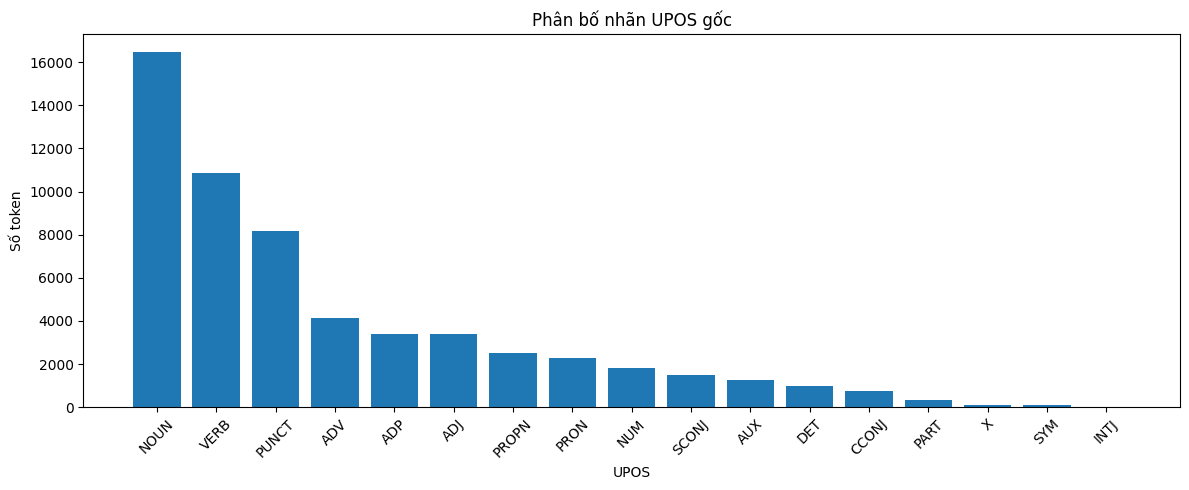

In [7]:
upos_counts = (
    token_df.groupby(["upos"])
    .size()
    .sort_values(ascending=False)
    .rename("count")
    .reset_index()
)
upos_counts["percentage"] = upos_counts["count"] / len(token_df) * 100
display(upos_counts)

plt.figure(figsize=(12, 5))
plt.bar(upos_counts["upos"], upos_counts["count"])
plt.title("Phân bố nhãn UPOS gốc")
plt.xlabel("UPOS")
plt.ylabel("Số token")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Kiểm tra chất lượng dữ liệu

Các kiểm tra gồm: nhãn UPOS thiếu, FORM thiếu, token có khoảng trắng, token bất thường và câu trùng lặp. Không tự động xóa câu trùng ở bước này; chỉ lập báo cáo để nhóm quyết định sau khi xem xét.

In [8]:
quality = {
    "Token thiếu FORM": int(token_df["form"].isna().sum() + (token_df["form"] == "").sum()),
    "Token thiếu UPOS": int(token_df["upos"].isna().sum() + (token_df["upos"] == "").sum()),
    "Token có khoảng trắng trong FORM": int(token_df["form"].str.contains(r"\s", regex=True, na=False).sum()),
    "Token có UPOS '_'": int((token_df["upos"] == "_").sum()),
}
display(pd.DataFrame([quality]).T.rename(columns={0: "Số lượng"}))

# Câu trùng: dùng chuỗi FORM theo đúng thứ tự; báo cáo trùng trong từng tập và giữa các tập.
sentence_df["surface_key"] = sentence_df["forms"].apply(
    lambda xs: " ".join(unicodedata.normalize("NFC", str(x)) for x in xs)
)

print("Câu trùng nội bộ theo từng tập:")
for split in ["train", "dev", "test"]:
    s = sentence_df[sentence_df["split"] == split]
    duplicated = int(s["surface_key"].duplicated(keep=False).sum())
    duplicate_excess = int(s["surface_key"].duplicated().sum())
    print(f"{split}: {duplicate_excess} bản ghi lặp dư; {duplicated} dòng thuộc nhóm trùng")

print("\nCâu giao nhau giữa các tập:")
sets = {
    split: set(sentence_df.loc[sentence_df["split"] == split, "surface_key"])
    for split in ["train", "dev", "test"]
}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    overlap = sets[a] & sets[b]
    print(f"{a} ∩ {b}: {len(overlap)} câu duy nhất")

,Số lượng
Token thiếu FORM,0
Token thiếu UPOS,0
Token có khoảng trắng trong FORM,12111
Token có UPOS '_',0


Câu trùng nội bộ theo từng tập:
train: 12 bản ghi lặp dư; 16 dòng thuộc nhóm trùng
dev: 2 bản ghi lặp dư; 4 dòng thuộc nhóm trùng
test: 6 bản ghi lặp dư; 7 dòng thuộc nhóm trùng

Câu giao nhau giữa các tập:
train ∩ dev: 2 câu duy nhất
train ∩ test: 1 câu duy nhất
dev ∩ test: 0 câu duy nhất


In [9]:
# ============================================================
# LOẠI BỎ:
# 1. Dấu câu: UPOS = PUNCT
# 2. Số từ: UPOS = NUM
# 3. Token có nội dung hoàn toàn là số
# ============================================================

def is_numeric_token(form):
    """
    Kiểm tra token có phải biểu diễn số hay không.

    Ví dụ bị loại:
    2025, 100, 3.14, 3,14, 25%, -10
    """

    form = unicodedata.normalize("NFC", str(form)).strip()

    # Chuyển chữ số Unicode về dạng ASCII nếu có thể
    normalized = form.translate(
        str.maketrans("０１２３４５６７８９", "0123456789")
    )

    # Chấp nhận số nguyên, số thập phân,
    # số âm/dương, phân tách hàng nghìn và phần trăm
    pattern = r"^[+-]?(?:\d+(?:[.,]\d+)*)(?:%)?$"

    return bool(re.fullmatch(pattern, normalized))


# Thống kê trước khi lọc
print("SỐ LƯỢNG TOKEN TRƯỚC KHI LỌC")

for split, sentences in data.items():
    total = sum(len(sent["tokens"]) for sent in sentences)
    print(f"{split.upper()}: {total:,} tokens")


# Thực hiện lọc
filter_stats = {}

for split, sentences in data.items():

    removed_punct = 0
    removed_num = 0
    removed_numeric_form = 0

    for sentence in sentences:

        original_tokens = sentence["tokens"]
        filtered_tokens = []

        for token in original_tokens:

            form = token["form"]
            upos = token["upos"]

            # Điều kiện 1: Loại dấu câu
            if upos == "PUNCT":
                removed_punct += 1
                continue

            # Điều kiện 2: Loại token có nhãn NUM
            if upos == "NUM":
                removed_num += 1
                continue

            # Điều kiện 3: Loại token có nội dung là số
            if is_numeric_token(form):
                removed_numeric_form += 1
                continue

            filtered_tokens.append(token)

        sentence["tokens"] = filtered_tokens

    # Loại các câu không còn token sau khi lọc
    data[split] = [
        sentence for sentence in sentences
        if len(sentence["tokens"]) > 0
    ]

    filter_stats[split] = {
        "punct": removed_punct,
        "num": removed_num,
        "numeric_form": removed_numeric_form
    }


# Hiển thị kết quả
print("\nKẾT QUẢ SAU KHI LỌC")

for split, sentences in data.items():

    remaining_tokens = sum(
        len(sent["tokens"]) for sent in sentences
    )

    stats = filter_stats[split]

    print(f"\n{split.upper()}")
    print(f"Số câu còn lại: {len(sentences):,}")
    print(f"Dấu câu đã loại: {stats['punct']:,}")
    print(f"Số token NUM đã loại: {stats['num']:,}")
    print(f"Token dạng số đã loại: {stats['numeric_form']:,}")
    print(f"Số token còn lại: {remaining_tokens:,}")


SỐ LƯỢNG TOKEN TRƯỚC KHI LỌC
DEV: 26,162 tokens
TEST: 11,692 tokens
TRAIN: 20,215 tokens

KẾT QUẢ SAU KHI LỌC

DEV
Số câu còn lại: 1,123
Dấu câu đã loại: 3,517
Số token NUM đã loại: 937
Token dạng số đã loại: 28
Số token còn lại: 21,680

TEST
Số câu còn lại: 800
Dấu câu đã loại: 1,703
Số token NUM đã loại: 269
Token dạng số đã loại: 0
Số token còn lại: 9,720

TRAIN
Số câu còn lại: 1,400
Dấu câu đã loại: 2,931
Số token NUM đã loại: 622
Token dạng số đã loại: 0
Số token còn lại: 16,662


In [10]:
# ============================================================
# LOẠI BỎ CÂU TRÙNG LẶP TRONG TRAIN / DEV / TEST
# Thứ tự ưu tiên: TRAIN > DEV > TEST
# Chỉ loại bỏ khi cả FORM và UPOS đều giống nhau
# ============================================================

import unicodedata
from collections import defaultdict

SPLIT_PRIORITY = ["train", "dev", "test"]

def normalize_for_duplicate_check(value):
    """Chuẩn hóa Unicode và khoảng trắng để so sánh."""
    value = unicodedata.normalize("NFC", str(value))
    return " ".join(value.split())


def get_sentence_signature(sentence):
    """
    Tạo khóa nhận diện câu từ:
    - FORM của từng token
    - UPOS tương ứng của từng token

    Giữ nguyên thứ tự token.
    """
    return tuple(
        (
            normalize_for_duplicate_check(token["form"]),
            token["upos"]
        )
        for token in sentence["tokens"]
    )


# Lưu dữ liệu ban đầu để có thể đối chiếu nếu cần
data_original = {
    split: sentences.copy()
    for split, sentences in data.items()
}

# Thống kê trước khi xử lý
print("SỐ LƯỢNG CÂU TRƯỚC KHI LOẠI TRÙNG")
for split in SPLIT_PRIORITY:
    print(f"{split}: {len(data[split]):,} câu")


# ------------------------------------------------------------
# BƯỚC 1: Phát hiện cùng nội dung nhưng khác nhãn UPOS
# ------------------------------------------------------------

surface_groups = defaultdict(list)

for split in SPLIT_PRIORITY:
    for sentence in data[split]:
        surface_key = tuple(
            normalize_for_duplicate_check(token["form"])
            for token in sentence["tokens"]
        )

        surface_groups[surface_key].append({
            "split": split,
            "sentence_id": sentence["sentence_id"],
            "signature": get_sentence_signature(sentence)
        })

conflicting_groups = []

for surface_key, records in surface_groups.items():
    signatures = {record["signature"] for record in records}

    # Cùng nội dung nhưng có nhiều chuỗi nhãn UPOS khác nhau
    if len(signatures) > 1:
        conflicting_groups.append(records)

print("\nSỐ NHÓM CÂU CÙNG NỘI DUNG NHƯNG KHÁC NHÃN:")
print(len(conflicting_groups))

# Không tự động xóa những trường hợp này.
conflict_rows = []

for group in conflicting_groups:
    for record in group:
        conflict_rows.append({
            "split": record["split"],
            "sentence_id": record["sentence_id"],
            "signature": record["signature"]
        })

conflict_df = pd.DataFrame(conflict_rows)
display(conflict_df.head(20))


# ------------------------------------------------------------
# BƯỚC 2: Loại bỏ câu trùng có cả FORM và UPOS giống nhau
# ------------------------------------------------------------

seen_signatures = set()
data_clean = {split: [] for split in SPLIT_PRIORITY}

removed_by_split = {split: 0 for split in SPLIT_PRIORITY}

for split in SPLIT_PRIORITY:
    for sentence in data[split]:

        signature = get_sentence_signature(sentence)

        if signature in seen_signatures:
            # Câu đã xuất hiện trước đó trong tập có ưu tiên cao hơn
            # hoặc đã xuất hiện trước đó trong chính tập hiện tại.
            removed_by_split[split] += 1
            continue

        data_clean[split].append(sentence)
        seen_signatures.add(signature)


# ------------------------------------------------------------
# BƯỚC 3: Cập nhật dữ liệu đã làm sạch
# ------------------------------------------------------------

data = data_clean

print("\nKẾT QUẢ SAU KHI LOẠI BỎ CÂU TRÙNG")
for split in SPLIT_PRIORITY:
    before = len(data_original[split])
    after = len(data[split])
    removed = removed_by_split[split]

    print(
        f"{split.upper():5} | "
        f"Trước: {before:,} | "
        f"Sau: {after:,} | "
        f"Đã loại: {removed:,}"
    )

total_before = sum(len(v) for v in data_original.values())
total_after = sum(len(v) for v in data.values())

print("-" * 55)
print(f"Tổng số câu trước: {total_before:,}")
print(f"Tổng số câu sau:   {total_after:,}")
print(f"Tổng số câu đã loại: {total_before - total_after:,}")


# ------------------------------------------------------------
# BƯỚC 4: Kiểm tra lại không còn câu trùng hoàn toàn
# ------------------------------------------------------------

all_signatures = []

for split in SPLIT_PRIORITY:
    for sentence in data[split]:
        all_signatures.append(get_sentence_signature(sentence))

assert len(all_signatures) == len(set(all_signatures)), \
    "Vẫn còn câu trùng hoàn toàn sau khi xử lý!"

print("\nKiểm tra thành công: Không còn câu trùng hoàn toàn.")


SỐ LƯỢNG CÂU TRƯỚC KHI LOẠI TRÙNG
train: 1,400 câu
dev: 1,123 câu
test: 800 câu

SỐ NHÓM CÂU CÙNG NỘI DUNG NHƯNG KHÁC NHÃN:
3


,split,sentence_id,signature
0,train,train_00132,"((Người, NOUN), (dân, NOUN), (tuân thủ, VERB),..."
1,dev,dev_00007,"((Người, NOUN), (dân, NOUN), (tuân thủ, VERB),..."
2,train,train_00456,"((Môi giới, NOUN), (mại dâm, VERB), (người, NO..."
3,train,train_00468,"((Môi giới, VERB), (mại dâm, VERB), (người, NO..."
4,dev,dev_00001,"((Trả lời, VERB), (phỏng vấn, VERB), (ông, NOU..."
5,dev,dev_00006,"((Trả lời, VERB), (phỏng vấn, VERB), (ông, NOU..."



KẾT QUẢ SAU KHI LOẠI BỎ CÂU TRÙNG
TRAIN | Trước: 1,400 | Sau: 1,389 | Đã loại: 11
DEV   | Trước: 1,123 | Sau: 1,121 | Đã loại: 2
TEST  | Trước: 800 | Sau: 793 | Đã loại: 7
-------------------------------------------------------
Tổng số câu trước: 3,323
Tổng số câu sau:   3,303
Tổng số câu đã loại: 20

Kiểm tra thành công: Không còn câu trùng hoàn toàn.


In [11]:
# Tạo lại sentence_df và token_df từ dữ liệu đã loại trùng

sentence_rows = []
token_rows = []

for split, sentences in data.items():
    for sent in sentences:
        tokens = sent["tokens"]

        sentence_rows.append({
            "split": split,
            "sentence_id": sent["sentence_id"],
            "n_tokens": len(tokens),
            "forms": [t["form"] for t in tokens],
            "upos": [t["upos"] for t in tokens],
        })

        for position, token in enumerate(tokens, start=1):
            token_rows.append({
                "split": split,
                "sentence_id": sent["sentence_id"],
                "position": position,
                **token
            })

sentence_df = pd.DataFrame(sentence_rows)
token_df = pd.DataFrame(token_rows)

print("KÍCH THƯỚC DỮ LIỆU SAU KHI LÀM SẠCH")
print("sentence_df:", sentence_df.shape)
print("token_df:", token_df.shape)

display(
    sentence_df.groupby("split").agg(
        so_cau=("sentence_id", "count"),
        so_token=("n_tokens", "sum")
    )
)


KÍCH THƯỚC DỮ LIỆU SAU KHI LÀM SẠCH
sentence_df: (3303, 5)
token_df: (47920, 13)


,so_cau,so_token
split,,
dev,1121,21645
test,793,9685
train,1389,16590


## 6. Phân tích độ dài câu và câu dài bất thường

Không loại câu dài chỉ vì chúng dài. Trước tiên xem phân vị và các câu vượt ngưỡng để quyết định `max_length` ở bước tokenizer.

,count,mean,median,min,max
split,,,,,
dev,1121,19.308653,18.0,2,78
test,793,12.213115,12.0,1,23
train,1389,11.943844,12.0,1,23


train P90 = 19.0 | P95 = 20.0 | P99 = 22.0
dev P90 = 31.0 | P95 = 37.0 | P99 = 54.799999999999955
test P90 = 19.0 | P95 = 21.0 | P99 = 22.0


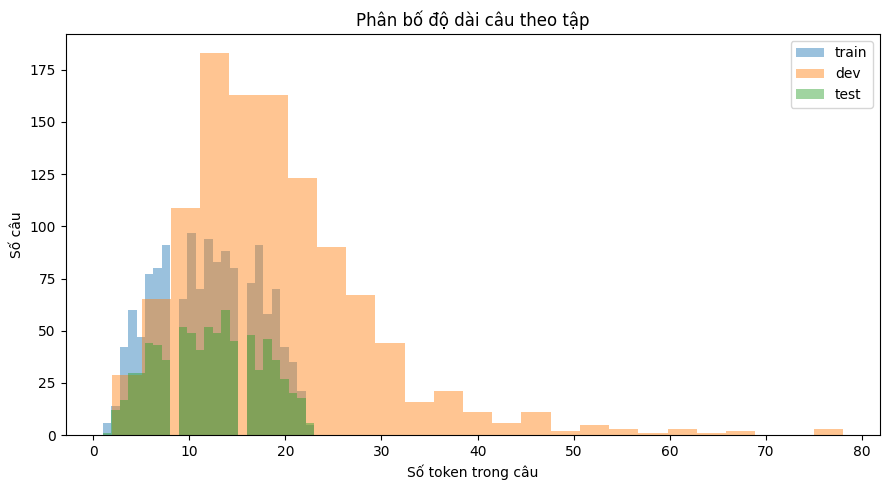

,split,sentence_id,n_tokens,forms
1916,dev,dev_00530,78,"[Cũng, trong, chương trình, đẩy mạnh, phát tri..."
2123,dev,dev_00737,77,"[Trong, khi, đó, tại, lễ, kỷ niệm, ngày, nước,..."
2108,dev,dev_00722,76,"[bác, tài, xe ôm, ngồi, chờ, khách, ngay, ngã,..."
1599,dev,dev_00212,66,"[Mới đây, nhà, nào, cũng, chỉ, với, cây, cột, ..."
1436,dev,dev_00049,66,"[Vượt, qua, những, con, đường, do, lũ lụt, tàn..."
2106,dev,dev_00720,64,"[Cơ sở, để, khẳng định, điều, đó, theo, luật s..."
1437,dev,dev_00050,62,"[Mặc dù, đã, tìm, nhiều, cách, để, lên, huyện,..."
2272,dev,dev_00886,62,"[Nhiệm vụ, quan trọng, nhất, của, chú, là, khô..."
2308,dev,dev_00922,60,"[Theo, báo cáo, tại, Hội nghị, từ, đầu, nhiệm ..."
1634,dev,dev_00247,59,"[Cô, cũng, không, đặt, ra, cột, mốc, sẽ, đưa, ..."


In [12]:
length_stats = (
    sentence_df.groupby("split")["n_tokens"]
    .agg(["count", "mean", "median", "min", "max"])
)
display(length_stats)

for split in ["train", "dev", "test"]:
    values = sentence_df.loc[sentence_df["split"] == split, "n_tokens"]
    print(
        split,
        "P90 =", values.quantile(0.90),
        "| P95 =", values.quantile(0.95),
        "| P99 =", values.quantile(0.99)
    )

plt.figure(figsize=(9, 5))
for split in ["train", "dev", "test"]:
    values = sentence_df.loc[sentence_df["split"] == split, "n_tokens"]
    plt.hist(values, bins=25, alpha=0.45, label=split)
plt.title("Phân bố độ dài câu theo tập")
plt.xlabel("Số token trong câu")
plt.ylabel("Số câu")
plt.legend()
plt.tight_layout()
plt.show()

display(
    sentence_df.sort_values("n_tokens", ascending=False)
    [["split", "sentence_id", "n_tokens", "forms"]]
    .head(10)
)

## 7. Ánh xạ UPOS thành 5 nhóm mục tiêu

Quy tắc ánh xạ ban đầu:
- Noun: `NOUN`, `PROPN`
- Verb: `VERB`, `AUX`
- Adjective: `ADJ`
- Adverb: `ADV`
- Other: các nhãn UPOS còn lại

Đây là quy ước của đề tài, cần được mô tả rõ trong báo cáo. Nếu giảng viên yêu cầu phân biệt trợ động từ hoặc đại từ, cần điều chỉnh bảng ánh xạ và chạy lại toàn bộ thống kê.

,Nhóm từ loại,Số token,Tỷ lệ (%)
0,Noun,18887,39.41
1,Verb,12129,25.31
2,Adjective,3375,7.04
3,Adverb,4139,8.64
4,Other,9390,19.60


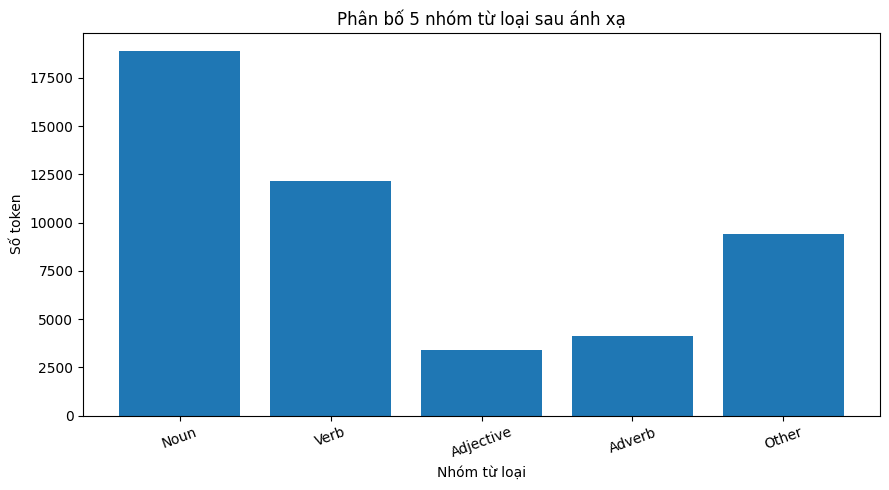

In [13]:
UPOS_TO_GROUP = {
    "NOUN": "Noun",
    "PROPN": "Noun",
    "VERB": "Verb",
    "AUX": "Verb",
    "ADJ": "Adjective",
    "ADV": "Adverb",
}

TARGET_LABELS = ["Noun", "Verb", "Adjective", "Adverb", "Other"]

def map_upos(upos):
    return UPOS_TO_GROUP.get(upos, "Other")

token_df["pos5"] = token_df["upos"].map(map_upos)

# Kiểm tra mọi nhãn gốc đều được ánh xạ thành đúng một trong 5 lớp.
assert token_df["pos5"].notna().all()
assert set(token_df["pos5"].unique()).issubset(set(TARGET_LABELS))

pos5_counts = (
    token_df["pos5"].value_counts()
    .reindex(TARGET_LABELS, fill_value=0)
    .rename_axis("Nhóm từ loại")
    .reset_index(name="Số token")
)
pos5_counts["Tỷ lệ (%)"] = (pos5_counts["Số token"] / len(token_df) * 100).round(2)
display(pos5_counts)

plt.figure(figsize=(9, 5))
plt.bar(pos5_counts["Nhóm từ loại"], pos5_counts["Số token"])
plt.title("Phân bố 5 nhóm từ loại sau ánh xạ")
plt.xlabel("Nhóm từ loại")
plt.ylabel("Số token")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. Phân bố 5 nhóm theo từng tập

Kiểm tra xem train/dev/test có phân bố nhãn tương đối tương đồng hay không. Đây là kiểm tra mô tả, không phải lý do để tự ý gộp và chia lại các tập.

pos5,Adjective,Adverb,Noun,Other,Verb
split,,,,,
dev,1561,1641,8859,4115,5469
test,719,1020,3561,2009,2376
train,1095,1478,6467,3266,4284


pos5,Adjective,Adverb,Noun,Other,Verb
split,,,,,
dev,7.21,7.58,40.93,19.01,25.27
test,7.42,10.53,36.77,20.74,24.53
train,6.60,8.91,38.98,19.69,25.82


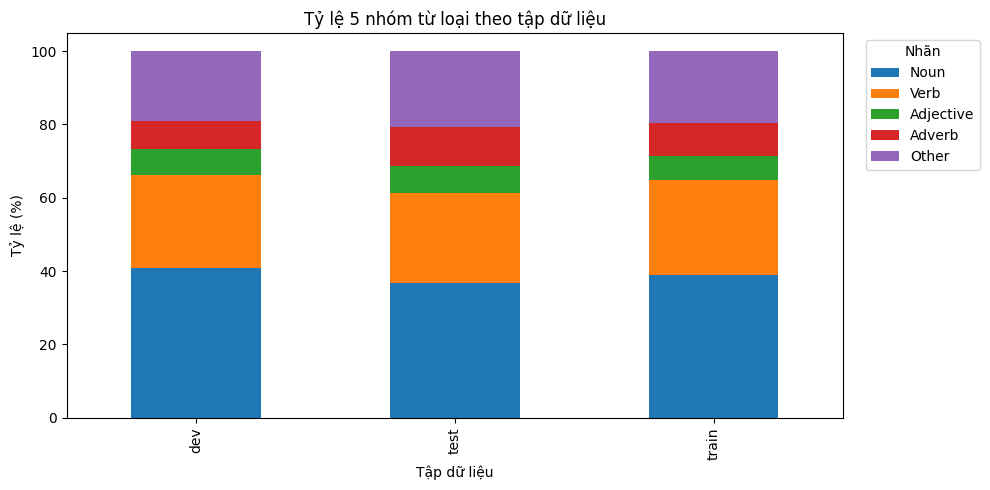

In [14]:
split_label_counts = pd.crosstab(token_df["split"], token_df["pos5"])
split_label_pct = pd.crosstab(
    token_df["split"], token_df["pos5"], normalize="index"
).mul(100).round(2)

display(split_label_counts)
display(split_label_pct)

ax = split_label_pct[TARGET_LABELS].plot(
    kind="bar", stacked=True, figsize=(10, 5)
)
ax.set_title("Tỷ lệ 5 nhóm từ loại theo tập dữ liệu")
ax.set_xlabel("Tập dữ liệu")
ax.set_ylabel("Tỷ lệ (%)")
ax.legend(title="Nhãn", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. Chuẩn hóa dữ liệu ở mức từ cho PhoBERT

Không tách từ lại. Một FORM có thể chứa nhiều tiếng, ví dụ `chủ tịch`; khi dựng chuỗi đầu vào PhoBERT, chuẩn hóa thành `chủ_tịch`. Đồng thời lưu riêng danh sách token và nhãn để giữ alignment.

Không lowercase toàn bộ dữ liệu và không xóa dấu câu ở bước này.

In [15]:
def normalize_form_for_phobert(form):
    form = unicodedata.normalize("NFC", str(form))
    # Một token CoNLL-U có thể gồm nhiều tiếng; nối các tiếng bằng underscore.
    form = re.sub(r"\s+", "_", form.strip())
    return form

processed_sentences = []

for split, sentences in data.items():
    for sent in sentences:
        original_tokens = [t["form"] for t in sent["tokens"]]
        labels = [map_upos(t["upos"]) for t in sent["tokens"]]
        model_tokens = [normalize_form_for_phobert(t) for t in original_tokens]

        processed_sentences.append({
            "split": split,
            "sentence_id": sent["sentence_id"],
            "tokens_original": original_tokens,
            "tokens_phobert": model_tokens,
            "labels": labels,
            "text_phobert": " ".join(model_tokens),
            "n_words": len(model_tokens)
        })

processed_df = pd.DataFrame(processed_sentences)

# Kiểm tra alignment ở mức từ.
assert all(
    len(row.tokens_phobert) == len(row.labels)
    for row in processed_df.itertuples()
)
assert all(
    len(row.tokens_original) == len(row.labels)
    for row in processed_df.itertuples()
)

display(processed_df.head(10)[
    ["split", "sentence_id", "tokens_original", "tokens_phobert", "labels", "text_phobert"]
])
print("Đã kiểm tra: số token gốc = số token chuẩn hóa = số nhãn trong mọi câu.")

,split,sentence_id,tokens_original,tokens_phobert,labels,text_phobert
0,train,train_00001,"[Tôi, nhớ, lời, anh, chủ tịch, xã, Bùi Văn Luy...","[Tôi, nhớ, lời, anh, chủ_tịch, xã, Bùi_Văn_Luy...","[Other, Verb, Noun, Noun, Noun, Noun, Noun, Ve...",Tôi nhớ lời anh chủ_tịch xã Bùi_Văn_Luyến nhắc...
1,train,train_00002,"[Hiện nay, xã, có, tổ, nhân dân, tổ, phụ trách...","[Hiện_nay, xã, có, tổ, nhân_dân, tổ, phụ_trách...","[Noun, Noun, Verb, Noun, Noun, Noun, Verb, Noun]",Hiện_nay xã có tổ nhân_dân tổ phụ_trách gia_đình
2,train,train_00003,"[Chủ trương, tốt, nhưng, dân, không, hiểu, khô...","[Chủ_trương, tốt, nhưng, dân, không, hiểu, khô...","[Noun, Adjective, Other, Noun, Adverb, Verb, A...",Chủ_trương tốt nhưng dân không hiểu không hưởn...
3,train,train_00004,"[Nên, trước nhất, người, đảng viên, phải, làm ...","[Nên, trước_nhất, người, đảng_viên, phải, làm_...","[Other, Noun, Noun, Noun, Verb, Verb]",Nên trước_nhất người đảng_viên phải làm_gương
4,train,train_00005,"[Riêng, về, xuất khẩu, lao động, anh, Luyến, c...","[Riêng, về, xuất_khẩu, lao_động, anh, Luyến, c...","[Other, Other, Verb, Noun, Noun, Noun, Verb, N...",Riêng về xuất_khẩu lao_động anh Luyến có cách ...
5,train,train_00006,"[Người, lao động, cũng, vậy]","[Người, lao_động, cũng, vậy]","[Noun, Noun, Adverb, Other]",Người lao_động cũng vậy
6,train,train_00007,"[Sau, năm, làm việc, ở, nước ngoài, bên, cạnh,...","[Sau, năm, làm_việc, ở, nước_ngoài, bên, cạnh,...","[Other, Noun, Verb, Other, Noun, Noun, Noun, N...",Sau năm làm_việc ở nước_ngoài bên cạnh việc tạ...
7,train,train_00008,"[Đến, nay, xã, có, người, đi, làm việc, ở, nướ...","[Đến, nay, xã, có, người, đi, làm_việc, ở, nướ...","[Other, Other, Noun, Verb, Noun, Verb, Verb, O...",Đến nay xã có người đi làm_việc ở nước_ngoài
8,train,train_00009,"[Khi, trở về, hầu hết, tiếp tục, làm việc, tốt]","[Khi, trở_về, hầu_hết, tiếp_tục, làm_việc, tốt]","[Noun, Verb, Adverb, Verb, Verb, Adjective]",Khi trở_về hầu_hết tiếp_tục làm_việc tốt
9,train,train_00010,"[Nhiều, người, từ, nghèo khó, nhất, xã, đã, có...","[Nhiều, người, từ, nghèo_khó, nhất, xã, đã, có...","[Adjective, Noun, Other, Adjective, Adverb, No...",Nhiều người từ nghèo_khó nhất xã đã có vốn mở ...


Đã kiểm tra: số token gốc = số token chuẩn hóa = số nhãn trong mọi câu.


## 10. Kiểm tra các token đa tiếng và ví dụ sau chuẩn hóa

Mục tiêu là xác nhận các token có khoảng trắng được nối bằng `_`, nhưng vẫn giữ nguyên số lượng token và nhãn.

In [16]:
multiword_examples = token_df[token_df["form"].str.contains(r"\s", regex=True, na=False)][
    ["split", "sentence_id", "position", "form", "upos", "pos5"]
].head(20).copy() 

multiword_examples["form_phobert"] = multiword_examples["form"].apply(
    normalize_form_for_phobert
)
display(multiword_examples)

,split,sentence_id,position,form,upos,pos5,form_phobert
4,train,train_00001,5,chủ tịch,NOUN,Noun,chủ_tịch
6,train,train_00001,7,Bùi Văn Luyến,PROPN,Noun,Bùi_Văn_Luyến
11,train,train_00001,12,Coi bộ,ADV,Adverb,Coi_bộ
14,train,train_00001,15,quan trọng,ADJ,Adjective,quan_trọng
16,train,train_00002,1,Hiện nay,NOUN,Noun,Hiện_nay
20,train,train_00002,5,nhân dân,NOUN,Noun,nhân_dân
22,train,train_00002,7,phụ trách,VERB,Verb,phụ_trách
23,train,train_00002,8,gia đình,NOUN,Noun,gia_đình
24,train,train_00003,1,Chủ trương,NOUN,Noun,Chủ_trương
31,train,train_00003,8,hưởng ứng,VERB,Verb,hưởng_ứng


## 11. Xuất dữ liệu đã tiền xử lý

Xuất mỗi câu thành một dòng CSV. Các cột danh sách được lưu dưới dạng JSON string để không mất ranh giới token/nhãn. Giữ nguyên split gốc. Không xuất file CoNLL-U đã sửa đè lên dữ liệu nguồn.

In [18]:
OUTPUT_DIR = PROJECT_ROOT / "Data" / "output_vtb"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

export_df = processed_df.copy()
for col in ["tokens_original", "tokens_phobert", "labels"]:
    export_df[col] = export_df[col].apply(
        lambda x: json.dumps(x, ensure_ascii=False)
    )

for split in ["train", "dev", "test"]:
    part = export_df[export_df["split"] == split].copy()
    output_path = OUTPUT_DIR / f"{split}_pos5.csv"
    part.to_csv(output_path, index=False, encoding="utf-8-sig")
    print(f"Đã lưu {output_path.relative_to(PROJECT_ROOT)} | {len(part):,} câu")

# Lưu bảng thống kê để dùng trong báo cáo.
summary_df.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False, encoding="utf-8-sig")
upos_counts.to_csv(OUTPUT_DIR / "upos_distribution.csv", index=False, encoding="utf-8-sig")
pos5_counts.to_csv(OUTPUT_DIR / "pos5_distribution.csv", index=False, encoding="utf-8-sig")

print("\nHoàn tất. Thư mục đầu ra:", OUTPUT_DIR.resolve())

Đã lưu Data\output_vtb\train_pos5.csv | 1,389 câu
Đã lưu Data\output_vtb\dev_pos5.csv | 1,121 câu
Đã lưu Data\output_vtb\test_pos5.csv | 793 câu

Hoàn tất. Thư mục đầu ra: D:\Downloads\new_data_science\NEW PROJECTS\Pos_tagging\Data\output_vtb


## 12. Checklist trước khi bàn giao cho nhóm mô hình

- [ ] Đã thống nhất dùng UPOS làm nhãn gốc.
- [ ] Đã thống nhất bảng ánh xạ 5 nhóm với giảng viên/nhóm.
- [ ] Đã loại bỏ kiểu số và dấu câu.
- [ ] Đã kiểm tra câu trùng trong và giữa các tập.
- [ ] Đã giữ nguyên split train/dev/test.
- [ ] Đã xác nhận mỗi câu có số token bằng số nhãn.
- [ ] Đã thống nhất chiến lược BPE/subword alignment cho PhoBERT.
- [ ] Đã chọn `max_length` sau khi xem phân bố độ dài *sau tokenizer*.
- [ ] Đã lưu phiên bản dataset và notebook để tái lập kết quả.

**Đầu ra bàn giao:** `train_pos5.csv`, `dev_pos5.csv`, `test_pos5.csv` cùng các bảng thống kê.